# 05 · Publication figures for the voting-network analysis

**DTU 02805 – Social Graphs and Interactions.** This notebook *draws* results that already exist in `network_analysis/outputs/` (baseline and temporal notebooks). It does **not** recompute the analysis, the statistical tests or the data. The only derived objects are (i) party-by-party means and pair counts recomputed from the existing pairwise table and checked against the existing party table, and (ii) a *drawing* subgraph for the network figure (a threshold backbone, plus a disparity-filter comparison), both documented below.

Course drawing rules followed (week 4, "Seeing structure in the hairball: backbones"; week 1, "Seeing a network"): find the **backbone first** and say how much was removed, **lay out the backbone** (not the full network), colour by **communities computed on the full network** (not on the backbone), size by strength, label the important nodes. Week 8: few figures, each caption says what is plotted, what the comparison is and what the reader should see.

| Figure | Content | Status |
|---|---|---|
| A | party × party voting-similarity heatmap | implemented |
| B | MP voting-similarity network (party colours; communities in a second panel) + backbone comparison | implemented |
| C | before vs after the 2022 election: all MPs, and continuing MPs on the same pairs | implemented |
| D | individual dissent rates with denominators | implemented |
| E | voting similarity vs speech similarity | **placeholder**: no validated speech outputs exist yet |

In [1]:
import sys, json, hashlib, re, time
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "network_analysis" / "src" / "networks.py").exists():
        ROOT = cand
        break
sys.path.insert(0, str(ROOT / "network_analysis" / "src"))
import networks as N
import plotting as P

P.set_style()
SEED = 2805
OUT = P.output_dir(ROOT)
TAB, TMP = ROOT / "network_analysis" / "outputs" / "tables", ROOT / "network_analysis" / "outputs" / "tables" / "temporal"
MIN_OVERLAP = 40         # the baseline notebook's main overlap threshold (figures A, B)
TAU = 0.9                # figure B: draw pairs agreeing on >= 90 % of their shared contested divisions
TAU_ALT = 0.7            # figure B2: the loosest threshold that still lies in the empty gap of the similarity distribution
DISPARITY_ALPHA = 0.2    # figure B2: disparity filter level (0.05 keeps no edge here)
LOW_N_PAIRS = 5          # figure A: cells resting on fewer MP pairs than this are hatched
SMALL_DENOMINATOR = 100  # figure D: MPs with fewer eligible party-divisions than this are hatched (a display rule)
N_LABELS = 5             # figure B: label the MPs with the highest weighted strength

def digest_outputs():
    base = ROOT / "network_analysis" / "outputs"
    return {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
            for p in sorted(base.rglob("*")) if p.is_file() and "publication" not in p.relative_to(base).parts and p.name != "figure_values.json"}
BEFORE = digest_outputs()

pairs = pd.read_csv(TAB / "pairwise_voting_similarity.csv")
metrics = pd.read_csv(TAB / "network_metrics.csv")
comms = pd.read_csv(TAB / "network_communities.csv")
dissent = pd.read_csv(TAB / "dissent_network_summary.csv")
party_ref = pd.read_csv(TAB / "party_pair_similarity.csv", index_col=0)
base_res = json.loads((ROOT / "network_analysis" / "outputs" / "results" / "network_results.json").read_text(encoding="utf-8"))
tres = json.loads((ROOT / "network_analysis" / "outputs" / "results" / "temporal" / "temporal_results.json").read_text(encoding="utf-8"))
cont_pairs = pd.read_csv(TMP / "continuing_mp_pair_comparison.csv")
SHOWN = {}                # every number printed on a figure is also stored here and re-checked at the end
FILES = {}                # exported files per figure
print("inputs loaded:", len(BEFORE), "existing output files protected")

inputs loaded: 51 existing output files protected


### Colour and print check

Seven parties are too many for colour alone. Every party therefore also has a **marker shape**, heatmaps and bars carry numbers or text labels, and the heatmaps use one sequential hue whose lightness is monotone. The table shows the grey-scale luminance of each party colour; pairs closer than 0.08 cannot be told apart in grey-scale and are separated by their marker shapes (figure B) or by labels (figure D).

In [2]:
lum = pd.Series({p: P.luminance(N.PARTY_COLORS[p]) for p in N.PARTY_ORDER}, name="luminance")
close = [(a, b, round(abs(lum[a] - lum[b]), 3)) for i, a in enumerate(N.PARTY_ORDER) for b in N.PARTY_ORDER[i + 1:] if abs(lum[a] - lum[b]) < 0.08]
display(pd.DataFrame({"colour": pd.Series(N.PARTY_COLORS), "marker": pd.Series(N.PARTY_MARKERS), "luminance": lum.round(3)}).loc[N.PARTY_ORDER])
print("party pairs with similar grey-scale luminance (need the marker shape / label to be told apart):")
for a, b, d in close:
    print(f"  {a} / {b}: {d}")

,colour,marker,luminance
Javnaðarflokkurin,#2a78d6,o,0.188
Tjóðveldi,#eb6834,s,0.278
Sambandsflokkurin,#1baf7a,^,0.323
Fólkaflokkurin,#eda100,D,0.435
Framsókn,#e87ba4,v,0.340
Miðflokkurin,#008300,P,0.162
Sjálvstýri,#6250d6,X,0.132


party pairs with similar grey-scale luminance (need the marker shape / label to be told apart):
  Javnaðarflokkurin / Miðflokkurin: 0.025
  Javnaðarflokkurin / Sjálvstýri: 0.056
  Tjóðveldi / Sambandsflokkurin: 0.045
  Tjóðveldi / Framsókn: 0.062
  Sambandsflokkurin / Framsókn: 0.017
  Miðflokkurin / Sjálvstýri: 0.03


## Figure A — party-by-party voting similarity

Mean voting similarity between MPs of every pair of parties, from the existing pairwise table (`pairwise_voting_similarity.csv`): similarity = matching For/Against votes ÷ contested divisions both MPs voted in, speech window 2020-07-29 to 2023-05-04. Only MP pairs with **at least 40 shared contested divisions** are included (the baseline overlap restriction). The diagonal is the mean over pairs of *different* MPs of the same party. Party = the party under which the MP cast most ballots in the window. Cells resting on fewer than 5 MP pairs are hatched and italic.

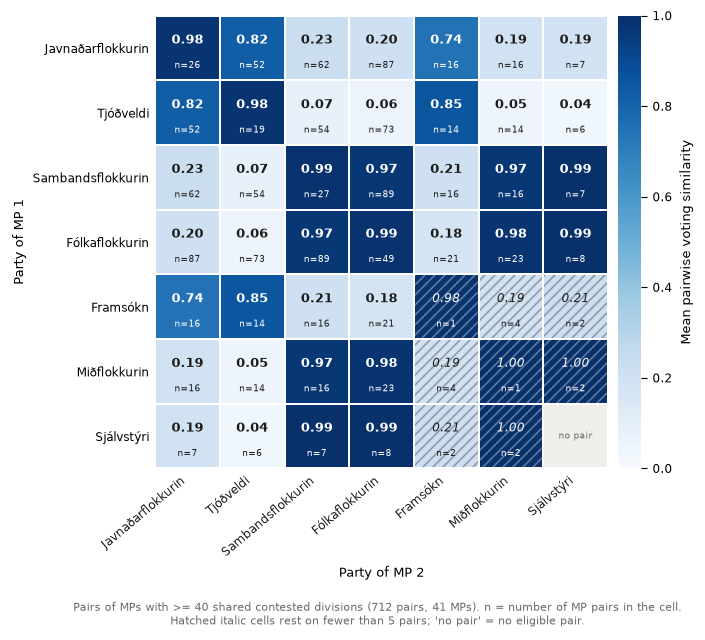

cells with fewer than 5 pairs: 6 of 28


In [3]:
mean_A, count_A = P.party_similarity_table(pairs, MIN_OVERLAP)

# verification against the existing party table (4-decimal CSV) and against the number of eligible pairs
diff = (mean_A - party_ref.loc[mean_A.index, mean_A.columns]).abs().stack().dropna()
assert diff.max() < 1e-3, diff.max()
n_elig = int((pairs.n_shared_divisions >= MIN_OVERLAP).sum())
assert int(np.triu(count_A.to_numpy()).sum()) == n_elig
n_mps_A = len(set(pairs[pairs.n_shared_divisions >= MIN_OVERLAP].mp_id_1) | set(pairs[pairs.n_shared_divisions >= MIN_OVERLAP].mp_id_2))

fig, ax = plt.subplots(figsize=(5.5, 4.9))
P.plot_party_heatmap(ax, mean_A, count_A, low_n=LOW_N_PAIRS)
ax.set_xlabel("Party of MP 2"); ax.set_ylabel("Party of MP 1")
fig.text(0.5, -0.115, f"Pairs of MPs with >= {MIN_OVERLAP} shared contested divisions ({n_elig} pairs, {n_mps_A} MPs). n = number of MP pairs in the cell.\nHatched italic cells rest on fewer than {LOW_N_PAIRS} pairs; 'no pair' = no eligible pair.",
         ha="center", va="top", fontsize=6.3, color=P.MUTED)
FILES["A"] = P.save_figure(fig, "figA_party_voting_similarity_heatmap", ROOT)
plt.show()
SHOWN["A"] = {"means": mean_A.round(6).astype(object).where(mean_A.notna(), None).to_dict(), "counts": count_A.to_dict(), "n_pairs": n_elig, "n_mps": n_mps_A}
print("cells with fewer than", LOW_N_PAIRS, "pairs:", int(((count_A < LOW_N_PAIRS) & (np.triu(np.ones(len(count_A)), 0) > 0)).to_numpy().sum()), "of", int(len(count_A) * (len(count_A) + 1) / 2))

## Figure B — the MP voting-similarity network

**Backbone first (week 4).** The full thresholded network (pairs with ≥ 40 shared contested divisions: 41 MPs, 712 pairs) is almost complete, so drawing all edges gives a hairball. Section B.1 documents the choices; the drawn network keeps pairs that agree on at least **τ = 0.9** of their shared contested divisions, and says how much was removed. **The backbone is for drawing only:** communities, strength and every statistic come from the full network (week 4: "detected on the full data, not on the backbone"). An absent edge means only "agreement below τ (or fewer than 40 shared divisions)", **not** that two MPs never voted alike.

In [4]:
# B.1 how many pairs does each candidate drawing rule keep?  (nothing here changes the analysis)
elig = pairs[pairs.n_shared_divisions >= MIN_OVERLAP]
node_party = {**dict(zip(pairs.mp_id_1, pairs.party_1)), **dict(zip(pairs.mp_id_2, pairs.party_2))}
names = metrics.set_index("mp_id").name
strength = metrics.set_index("mp_id").strength.to_dict()
G_full = N.similarity_graph(pairs, MIN_OVERLAP, pd.Series(node_party), names, sorted(set(elig.mp_id_1) | set(elig.mp_id_2)))
rows = []
for tau in (0.5, 0.6, 0.7, 0.8, 0.9, 0.95):
    kept = elig[elig.similarity >= tau]
    rows.append({"tau": tau, "pairs kept": len(kept), "share of 712": f"{len(kept) / len(elig):.0%}", "MPs with >= 1 kept pair": len(set(kept.mp_id_1) | set(kept.mp_id_2))})
tab_tau = pd.DataFrame(rows).set_index("tau")
display(tab_tau)
hist_gap = int(((elig.similarity >= 0.4) & (elig.similarity < 0.7)).sum())
print(f"pairs with similarity in [0.4, 0.7): {hist_gap} of {len(elig)}  -> any tau between 0.5 and 0.7 gives the same high-agreement graph; tau = {TAU} is a stricter legibility choice")
H_alpha = N.disparity_filter(G_full, DISPARITY_ALPHA)
H_005 = N.disparity_filter(G_full, 0.05)
print(f"disparity filter (week 4): alpha=0.05 keeps {H_005.number_of_edges()} edges; alpha={DISPARITY_ALPHA} keeps {H_alpha.number_of_edges()} edges "
      f"and leaves {sum(1 for n, d in H_alpha.degree() if d == 0)} of {H_alpha.number_of_nodes()} MPs without an edge")

,pairs kept,share of 712,MPs with >= 1 kept pair
tau,,,
0.50,350,49%,41
0.60,350,49%,41
0.70,349,49%,41
0.80,322,45%,41
0.90,258,36%,41
0.95,238,33%,41


pairs with similarity in [0.4, 0.7): 2 of 712  -> any tau between 0.5 and 0.7 gives the same high-agreement graph; tau = 0.9 is a stricter legibility choice
disparity filter (week 4): alpha=0.05 keeps 0 edges; alpha=0.2 keeps 279 edges and leaves 0 of 41 MPs without an edge


In [5]:
# B.2 the drawn network: layout of the backbone, size = strength (full network), label the highest-strength MPs
B = P.threshold_backbone(pairs, MIN_OVERLAP, TAU)
pos = P.component_layout(B, SEED)
isolated = sorted(set(G_full.nodes) - set(B.nodes), key=lambda n: -strength[n])
comm = comms.set_index("mp_id").community
assert all(comm[n] >= 0 for n in G_full.nodes)                     # every drawn MP belongs to the full-graph Louvain partition
sizes_comm = comm[comm >= 0].value_counts().sort_index()
COMM_FILL = {0: "#3d3d3b", 1: "#ffffff"}
top = sorted(B.nodes, key=lambda n: -strength[n])[:N_LABELS]
labels = {n: names[n] for n in top}
print(f"backbone: {B.number_of_edges()} of {len(elig)} pairs kept, {B.number_of_nodes()} of {G_full.number_of_nodes()} MPs have an edge; "
      f"{len(isolated)} MPs have no pair >= {TAU}: {[names[n] for n in isolated]}")
print("components of the backbone:", sorted((len(c) for c in nx.connected_components(B)), reverse=True))
print("labelled MPs (highest weighted strength in the full network):", [names[n] for n in top])

backbone: 258 of 712 pairs kept, 41 of 41 MPs have an edge; 0 MPs have no pair >= 0.9: []
components of the backbone: [24, 9, 8]
labelled MPs (highest weighted strength in the full network): ['Beinir Johannesen', 'Erhard Joensen', 'Steffan Klein Poulsen', 'Edva Jacobsen', 'Jógvan á Lakjuni']


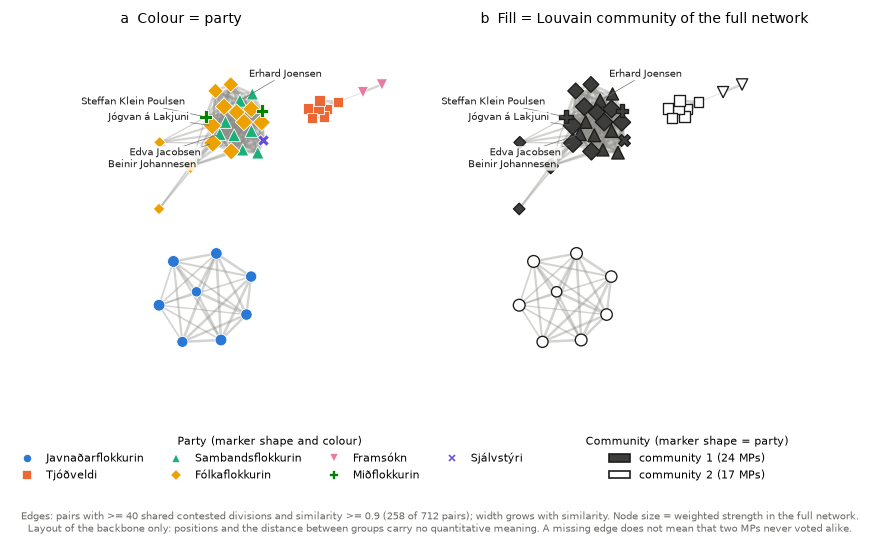

In [6]:
def place_isolated(pos, nodes):
    """MPs without a backbone edge are shown in a row below the network, not hidden."""
    if not nodes:
        return {}
    xs, ys = [p[0] for p in pos.values()], [p[1] for p in pos.values()]
    y0 = min(ys) - 0.5
    x = np.linspace(min(xs), max(xs), len(nodes) + 2)[1:-1]
    return {n: np.array([xx, y0]) for n, xx in zip(nodes, x)}

fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.9))
pos_all = {**pos, **place_isolated(pos, isolated)}
B_all = B.copy(); B_all.add_nodes_from(isolated)
offsets = P.outward_offsets(B, pos, set(top))
for ax, fill, ttl in ((axes[0], None, "a  Colour = party"), (axes[1], {n: COMM_FILL[comm[n]] for n in B_all.nodes}, "b  Fill = Louvain community of the full network")):
    P.draw_similarity_network(ax, B_all, pos_all, node_party, strength, TAU, node_fill=fill, labels=labels, label_offsets=offsets)
    ax.set_title(ttl, loc="left", fontsize=8.2)
if isolated:
    axes[0].text(np.mean([pos_all[n][0] for n in isolated]), min(pos_all[n][1] for n in isolated) - 0.12, f"{len(isolated)} MPs with no pair agreeing on >= {TAU:.0%}",
                 ha="center", va="top", fontsize=6, color=P.MUTED)
h_party = P.party_legend_handles([p for p in N.PARTY_ORDER if p in set(node_party[n] for n in B_all.nodes)])
fig.legend(handles=h_party, loc="upper center", ncol=4, bbox_to_anchor=(0.30, 0.04), title="Party (marker shape and colour)", fontsize=6.4, title_fontsize=6.4)
fig.legend(handles=[Patch(facecolor=COMM_FILL[0], edgecolor=P.INK, label=f"community 1 ({sizes_comm[0]} MPs)"),
                    Patch(facecolor=COMM_FILL[1], edgecolor=P.INK, label=f"community 2 ({sizes_comm[1]} MPs)")],
           loc="upper center", ncol=1, bbox_to_anchor=(0.79, 0.04), title="Community (marker shape = party)", fontsize=6.4, title_fontsize=6.4)
fig.text(0.5, -0.14, f"Edges: pairs with >= {MIN_OVERLAP} shared contested divisions and similarity >= {TAU} ({B.number_of_edges()} of {len(elig)} pairs); width grows with similarity. "
         f"Node size = weighted strength in the full network.\nLayout of the backbone only: positions and the distance between groups carry no quantitative meaning. A missing edge does not mean that two MPs never voted alike.",
         ha="center", va="top", fontsize=5.9, color=P.MUTED)
FILES["B"] = P.save_figure(fig, "figB_mp_voting_similarity_network", ROOT)
plt.show()
SHOWN["B"] = {"tau": TAU, "edges": B.number_of_edges(), "pairs_eligible": len(elig), "mps_drawn": G_full.number_of_nodes(), "mps_with_backbone_edge": B.number_of_nodes(),
              "isolated": [names[n] for n in isolated], "community_sizes": {int(k): int(v) for k, v in sizes_comm.items()}, "labels": [names[n] for n in top]}

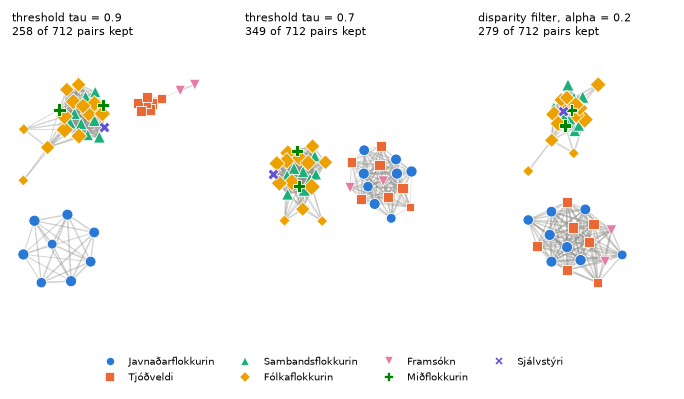

In [7]:
# B2 (supplement): the three drawing rules side by side, so the choice can be judged
variants = [(f"threshold tau = {TAU}", P.threshold_backbone(pairs, MIN_OVERLAP, TAU), TAU),
            (f"threshold tau = {TAU_ALT}", P.threshold_backbone(pairs, MIN_OVERLAP, TAU_ALT), TAU_ALT),
            (f"disparity filter, alpha = {DISPARITY_ALPHA}", H_alpha, 0.0)]
fig, axes = plt.subplots(1, 3, figsize=(7.1, 3.0))
for ax, (ttl, Gv, tau_v) in zip(axes, variants):
    Gv = nx.Graph(Gv); Gv.remove_nodes_from([n for n, d in list(Gv.degree()) if d == 0])
    pv = P.component_layout(Gv, SEED)
    iso_v = sorted(set(G_full.nodes) - set(Gv.nodes), key=lambda n: -strength[n])
    pv_all = {**pv, **place_isolated(pv, iso_v)}
    Gv_all = Gv.copy(); Gv_all.add_nodes_from(iso_v)
    P.draw_similarity_network(ax, Gv_all, pv_all, node_party, strength, tau_v, size_range=(10, 55), width_range=(0.2, 1.0))
    ax.set_title(f"{ttl}\n{Gv.number_of_edges()} of {len(elig)} pairs kept" + (f"; {len(iso_v)} MPs without an edge" if iso_v else ""), loc="left", fontsize=6.4)
fig.legend(handles=h_party, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.04), fontsize=6.2)
FILES["B2"] = P.save_figure(fig, "figB2_backbone_comparison", ROOT)
plt.show()
SHOWN["B2"] = {"threshold_0.9_edges": variants[0][1].number_of_edges(), "threshold_0.7_edges": variants[1][1].number_of_edges(), "disparity_edges": H_alpha.number_of_edges(), "disparity_0.05_edges": H_005.number_of_edges()}

## Figure C — before vs after the 8 December 2022 election

Two populations, **kept separate** (rows): *all MPs* of each parliament (each period's own eligible pairs; the MPs differ between periods) and the *continuing MPs* (the same MPs and the same MP pairs in both periods, so only the votes change). Metrics: mean voting similarity within parties, between parties, and Louvain modularity, all from the temporal notebook (threshold 20 shared contested divisions; post-election = full period to 2024-05-23). No confidence intervals are shown because none were calculated for these descriptive statistics. The timeline explains the 91-day gap: it contains the election, the change of government and the winter, so the first observed post-election division (not an event date) cannot be attributed to any one of them.

In [8]:
comp = tres["composition_comparison"]
pre_s, post_s = comp["pre"], comp["post_full"]
tl = tres["timeline"]
THR = tres["threshold"]["recommended"]
# same MPs, same pairs: within/between means over the pairs eligible in both periods, each period's own party labels
e = cont_pairs[cont_pairs.eligible_both].copy()
cont_pre = {"within": e.similarity_pre[e.same_party_pre].mean(), "between": e.similarity_pre[~e.same_party_pre].mean()}
cont_post = {"within": e.similarity_post[e.same_party_post].mean(), "between": e.similarity_post[~e.same_party_post].mean()}
cs = tres["continuing"]
n_cont_mps = len(set(e.mp_id_1) | set(e.mp_id_2))
assert len(e) == cs["n_pairs_eligible_both"]
SHOWN["C"] = {"all": {"within": {"pre": pre_s["mean_within"], "post": post_s["mean_within"]}, "between": {"pre": pre_s["mean_between"], "post": post_s["mean_between"]},
                      "modularity": {"pre": pre_s["louvain_modularity"], "post": post_s["louvain_modularity"]}},
              "continuing": {"within": {"pre": cont_pre["within"], "post": cont_post["within"]}, "between": {"pre": cont_pre["between"], "post": cont_post["between"]},
                             "modularity": {"pre": cs["modularity_pre"], "post": cs["modularity_post"]}},
              "n": {"all_pre_mps": pre_s["n_mps_with_edge"], "all_post_mps": post_s["n_mps_with_edge"], "all_pre_pairs": pre_s["n_pairs_eligible"],
                    "all_post_pairs": post_s["n_pairs_eligible"], "cont_mps": n_cont_mps, "cont_pairs": len(e)}}
print(json.dumps(SHOWN["C"]["n"]))

{"all_pre_mps": 44, "all_post_mps": 33, "all_pre_pairs": 815, "all_post_pairs": 528, "cont_mps": 16, "cont_pairs": 113}


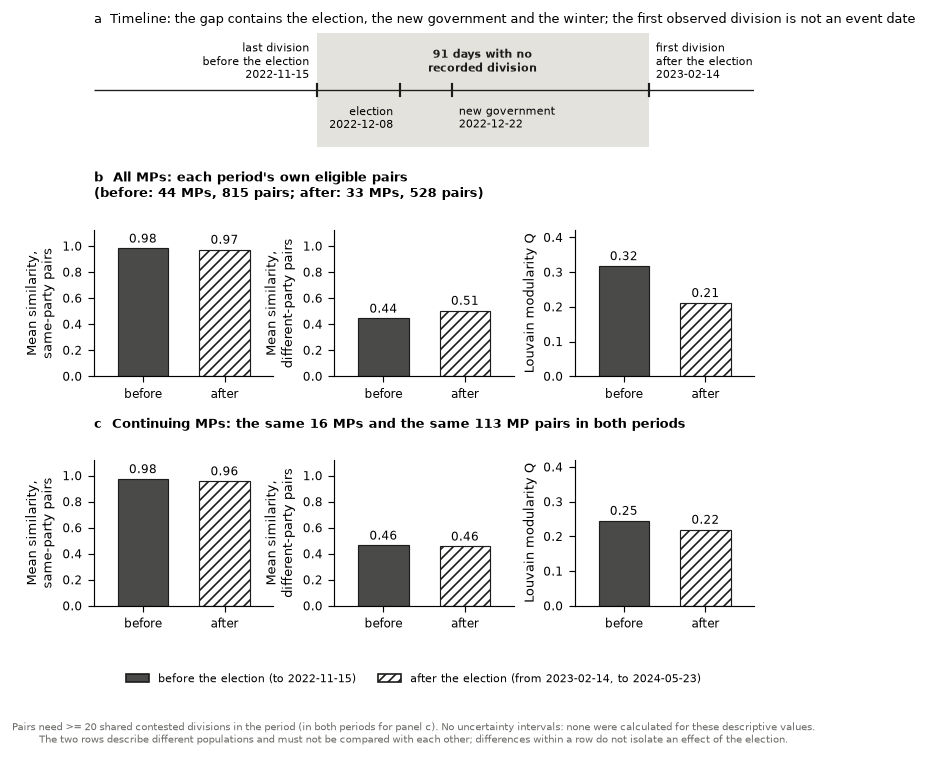

In [9]:
D = lambda s: pd.Timestamp(s)
fig = plt.figure(figsize=(7.1, 6.2))
gs = fig.add_gridspec(3, 3, height_ratios=[0.78, 1, 1], hspace=0.62, wspace=0.34)
# --- timeline strip
axt = fig.add_subplot(gs[0, :])
last_pre, first_post = D(tl["last_vote_before_election"]), D(tl["first_vote_after_election"])
elect, gov = D(tres["parameters"]["election"]), D(tres["parameters"]["new_government"])
axt.axvspan(last_pre, first_post, color="#e3e2dd", lw=0)
axt.hlines(0, D("2022-09-15"), D("2023-03-15"), color=P.INK, lw=0.8)
for d, lab, y, ha in ((last_pre, f"last division\nbefore the election\n{last_pre.date()}", 0.55, "right"), (elect, f"election\n{elect.date()}", -0.55, "right"),
                      (gov, f"new government\n{gov.date()}", -0.55, "left"), (first_post, f"first division\nafter the election\n{first_post.date()}", 0.55, "left")):
    axt.plot([d, d], [-0.12, 0.12], color=P.INK, lw=1.3)
    axt.text(d + pd.Timedelta(days=(-2 if ha == "right" else 2)), y, lab, ha=ha, va="center", fontsize=6.4)
axt.text(last_pre + (first_post - last_pre) / 2, 0.55, f"{tl['days_between']} days with no\nrecorded division", ha="center", va="center", fontsize=6.6, color=P.INK, fontweight="bold")
axt.set_ylim(-1.1, 1.1); axt.set_xlim(D("2022-09-15"), D("2023-03-15")); axt.set_axis_off()
axt.set_title("a  Timeline: the gap contains the election, the new government and the winter; the first observed division is not an event date", loc="left", fontsize=7.6)
# --- metric panels
specs = [("within", "Mean similarity,\nsame-party pairs", (0, 1.12), "{:.2f}"), ("between", "Mean similarity,\ndifferent-party pairs", (0, 1.12), "{:.2f}"),
         ("modularity", "Louvain modularity Q", (0, 0.42), "{:.2f}")]
row_titles = {0: f"b  All MPs: each period's own eligible pairs\n(before: {pre_s['n_mps_with_edge']} MPs, {pre_s['n_pairs_eligible']} pairs; after: {post_s['n_mps_with_edge']} MPs, {post_s['n_pairs_eligible']} pairs)",
              1: f"c  Continuing MPs: the same {n_cont_mps} MPs and the same {len(e)} MP pairs in both periods"}
for r, key in enumerate(("all", "continuing")):
    for c, (metric, yl, ylim, fm) in enumerate(specs):
        ax = fig.add_subplot(gs[r + 1, c])
        P.paired_bars(ax, SHOWN["C"][key][metric], yl, "", ylim=ylim, fmt=fm)
        if c == 0:
            ax.text(0, 1.20, row_titles[r], transform=ax.transAxes, fontsize=7.6, fontweight="bold", va="bottom")
fig.legend(handles=[Patch(facecolor=P.PRE_FILL, edgecolor=P.INK, label="before the election (to 2022-11-15)"),
                    Patch(facecolor="white", edgecolor=P.INK, hatch="////", label=f"after the election (from {first_post.date()}, to {tl['latest_vote']})")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01), fontsize=6.8)
fig.text(0.5, -0.045, f"Pairs need >= {THR} shared contested divisions in the period (in both periods for panel c). No uncertainty intervals: none were calculated for these descriptive values.\n"
         "The two rows describe different populations and must not be compared with each other; differences within a row do not isolate an effect of the election.",
         ha="center", va="top", fontsize=6.0, color=P.MUTED)
FILES["C"] = P.save_figure(fig, "figC_pre_post_election_comparison", ROOT)
plt.show()

## Figure D — individual dissent

From the existing `dissent_network_summary.csv` (exploratory definition of the baseline notebook): a *dissent* is a For/Against vote against the strict For/Against plurality of the MP's own party in a division where at least 3 party members cast For or Against and the party was not tied (party at the time of the vote). **Absence and blank votes are neither dissent nor support**, and are not in the denominator. The denominator is the MP's number of such *eligible party-divisions*. Rates are tiny and rest on 1–12 events, so each bar is printed with `dissents / eligible`; MPs with fewer than 100 eligible party-divisions are hatched. Only MPs with at least one dissent are drawn.

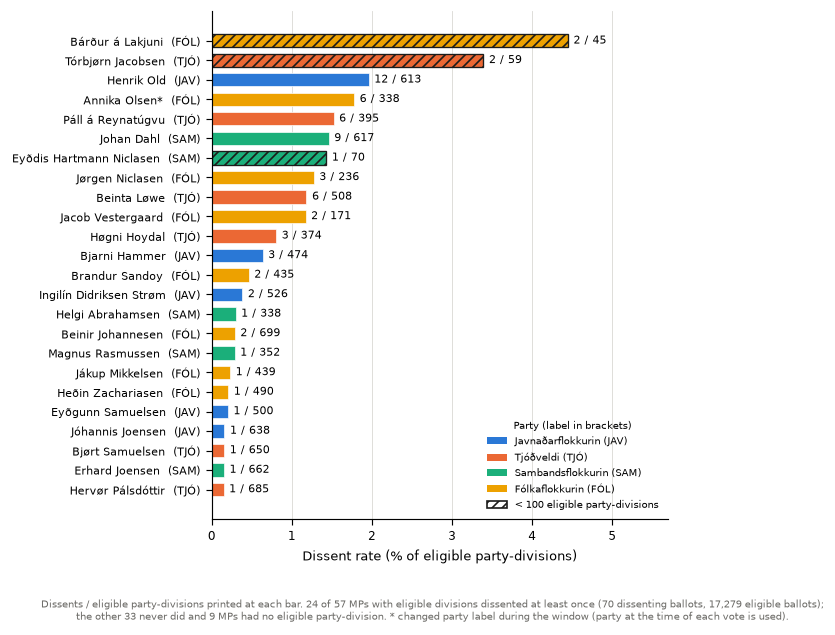

['Eyðdis Hartmann Niclasen', 'Tórbjørn Jacobsen', 'Bárður á Lakjuni']


In [10]:
dd = dissent[dissent.n_party_divisions.notna()].copy()
n_with_units, n_dis, n_events, n_total_elig = len(dd), int((dd.n_dissent > 0).sum()), int(dd.n_dissent.sum()), int(dd.n_party_divisions.sum())
n_no_units = len(dissent) - n_with_units
show = dd[dd.n_dissent > 0].sort_values(["dissent_rate", "n_dissent"], ascending=True)
ABBR = {"Javnaðarflokkurin": "JAV", "Tjóðveldi": "TJÓ", "Sambandsflokkurin": "SAM", "Fólkaflokkurin": "FÓL", "Framsókn": "FRA", "Miðflokkurin": "MIÐ", "Sjálvstýri": "SJÁ"}
switchers = set(base_res["data"]["party_switchers"])
fig, ax = plt.subplots(figsize=(4.9, 5.5))
y = np.arange(len(show))
for yi, (_, r) in zip(y, show.iterrows()):
    small = r.n_party_divisions < SMALL_DENOMINATOR
    ax.barh(yi, 100 * r.dissent_rate, height=0.68, color=N.PARTY_COLORS[r.party], edgecolor=P.INK if small else "white", lw=0.8 if small else 0.4,
            hatch="////" if small else None)
    ax.text(100 * r.dissent_rate + 0.07, yi, f"{int(r.n_dissent)} / {int(r.n_party_divisions)}", va="center", ha="left", fontsize=6.3)
ax.set_yticks(y)
ax.set_yticklabels([f"{r['name']}{'*' if r.mp_id in switchers else ''}  ({ABBR[r.party]})" for _, r in show.iterrows()], fontsize=6.4)
ax.set_xlabel("Dissent rate (% of eligible party-divisions)")
ax.set_xlim(0, 100 * show.dissent_rate.max() * 1.28)
ax.xaxis.grid(True, color=P.GRID, lw=0.5); ax.set_axisbelow(True)
hs = [Patch(facecolor=N.PARTY_COLORS[p], label=f"{p} ({ABBR[p]})") for p in N.PARTY_ORDER if p in set(show.party)]
hs.append(Patch(facecolor="white", edgecolor=P.INK, hatch="////", label=f"< {SMALL_DENOMINATOR} eligible party-divisions"))
ax.legend(handles=hs, loc="lower right", fontsize=6.0, title="Party (label in brackets)", title_fontsize=6.0)
fig.text(0.5, -0.01, f"Dissents / eligible party-divisions printed at each bar. {n_dis} of {n_with_units} MPs with eligible divisions dissented at least once ({n_events} dissenting ballots, {n_total_elig:,} eligible ballots);\n"
         f"the other {n_with_units - n_dis} never did and {n_no_units} MPs had no eligible party-division. * changed party label during the window (party at the time of each vote is used).",
         ha="center", va="top", fontsize=5.8, color=P.MUTED)
FILES["D"] = P.save_figure(fig, "figD_individual_dissent", ROOT)
plt.show()
SHOWN["D"] = {"mps_plotted": len(show), "n_with_units": n_with_units, "n_dissenting_mps": n_dis, "n_events": n_events, "n_eligible": n_total_elig, "n_no_units": n_no_units,
              "small_denominator_mps": [r["name"] for _, r in show.iterrows() if r.n_party_divisions < SMALL_DENOMINATOR]}
print(SHOWN["D"]["small_denominator_mps"])

## Figure E — voting similarity vs speech similarity (placeholder)

Not implemented. The cell below looks for validated speech-similarity outputs and for a join to the common MP-pair sample. If none exist it documents what is required.

In [11]:
speech_candidates = [p for p in ROOT.rglob("*") if p.is_file() and ".venv" not in p.parts and ".git" not in p.parts and "publication" not in p.parts
                     and re.search(r"speech|tfidf|tf_idf|embedding", p.name, re.I) and p.suffix in (".csv", ".parquet", ".json")]
speech_candidates = [p for p in speech_candidates if "fpsc" not in p.parts]
common = pd.read_csv(TMP / "common_pair_sample.csv")
print("speech-similarity output files found:", [str(p.relative_to(ROOT)) for p in speech_candidates] or "none")
print("common pair sample available for the join:", len(common), "pairs; key columns mp_id_1, mp_id_2")
REQUIRED_E = ["mp_id_1", "mp_id_2", "speech_similarity", "n_cases_or_documents_per_pair", "representation / method name", "minimum-words rule", "topic-control method"]
E_STATUS = {"speech_outputs_found": [str(p.relative_to(ROOT)) for p in speech_candidates], "common_pairs": len(common), "required_columns": REQUIRED_E}

speech-similarity output files found: none
common pair sample available for the join: 1081 pairs; key columns mp_id_1, mp_id_2


## Overview sheet, validation and README

The overview image shows the completed figures at reduced size (figure E as a placeholder tile). The checks re-read the source CSV/JSON files and compare every number that was printed on a figure; they also confirm that all exports exist and are readable and that no earlier output changed.

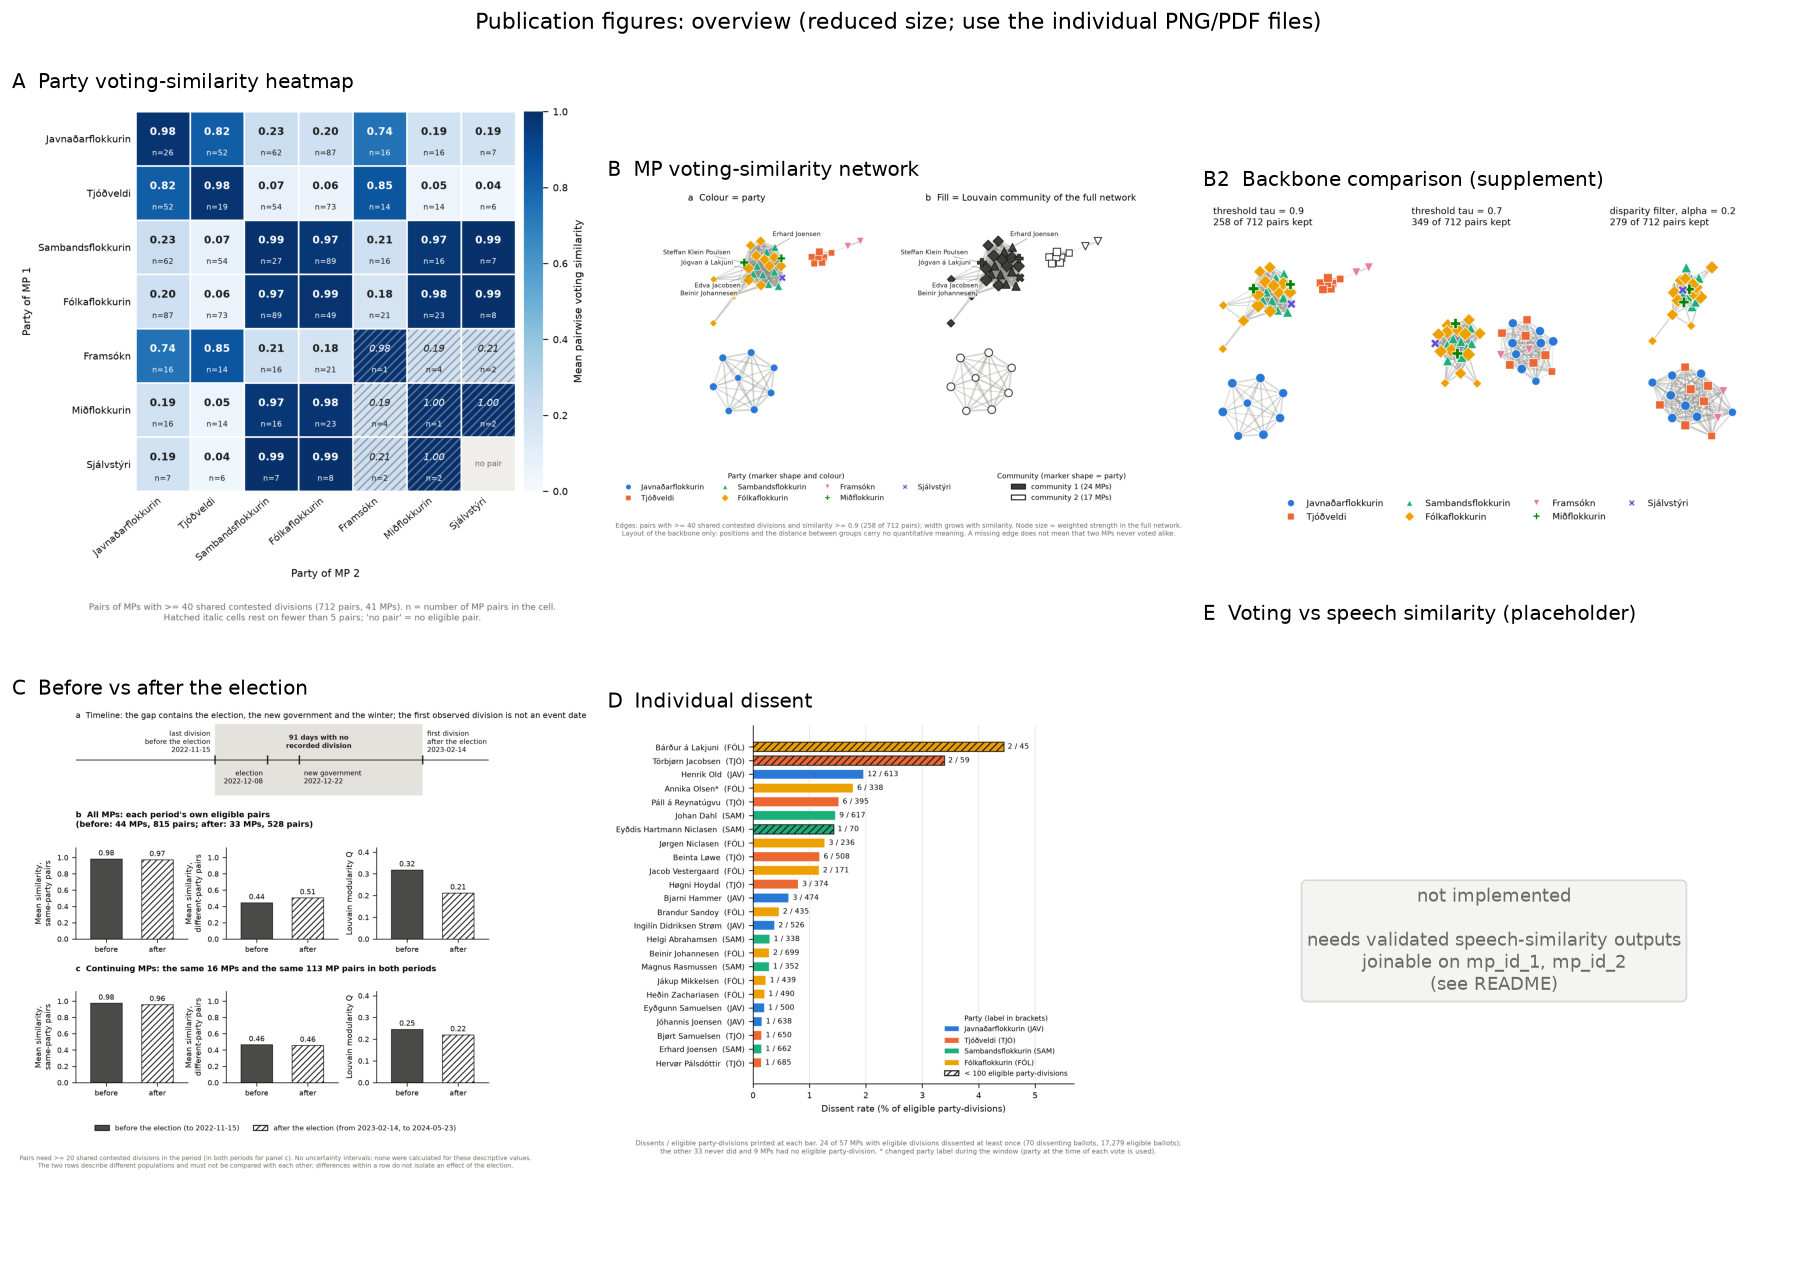

In [12]:
import matplotlib.image as mpimg
tiles = [("A", "figA_party_voting_similarity_heatmap", "A  Party voting-similarity heatmap"), ("B", "figB_mp_voting_similarity_network", "B  MP voting-similarity network"),
         ("B2", "figB2_backbone_comparison", "B2  Backbone comparison (supplement)"), ("C", "figC_pre_post_election_comparison", "C  Before vs after the election"),
         ("D", "figD_individual_dissent", "D  Individual dissent"), ("E", None, "E  Voting vs speech similarity (placeholder)")]
fig, axs = plt.subplots(2, 3, figsize=(15, 10.5))
for ax, (k, stem, ttl) in zip(axs.ravel(), tiles):
    ax.set_axis_off()
    if stem:
        ax.imshow(mpimg.imread(OUT / f"{stem}.png"))
    else:
        ax.text(0.5, 0.5, "not implemented\n\nneeds validated speech-similarity outputs\njoinable on mp_id_1, mp_id_2\n(see README)", ha="center", va="center", fontsize=11, color=P.MUTED,
                bbox={"boxstyle": "round", "fc": "#f4f4f2", "ec": P.GRID})
    ax.set_title(ttl, fontsize=12, loc="left")
fig.suptitle("Publication figures: overview (reduced size; use the individual PNG/PDF files)", fontsize=13, y=0.995)
fig.tight_layout()
FILES["overview"] = {"png": OUT / "overview_contact_sheet.png"}
fig.savefig(FILES["overview"]["png"], dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# ------------------------------------------------ README (generated from the computed values above)
def fill(t, **kw):
    for k, v in kw.items():
        t = t.replace(f"[[{k}]]", str(v))
    left = re.findall(r"\[\[(\w+)\]\]", t)
    assert not left, left
    return t

off = [(a, b, mean_A.loc[a, b], int(count_A.loc[a, b])) for i, a in enumerate(N.PARTY_ORDER) for b in N.PARTY_ORDER[i + 1:]
       if count_A.loc[a, b] >= LOW_N_PAIRS and not np.isnan(mean_A.loc[a, b])]
high_off = "; ".join(f"{a}-{b} {v:.2f} (n={c})" for a, b, v, c in sorted(off, key=lambda t: -t[2]) if v >= 0.7)
low_vals = [v for _, _, v, _ in off if v < 0.5]
diag_ok = [(p, mean_A.loc[p, p], int(count_A.loc[p, p])) for p in N.PARTY_ORDER if count_A.loc[p, p] >= LOW_N_PAIRS]
diag_txt = ", ".join(f"{p} {v:.2f} (n={c})" for p, v, c in diag_ok)
cvals = SHOWN["C"]; cn = cvals["n"]
f2 = lambda x: f"{x:.2f}"
small_txt = ", ".join(SHOWN["D"]["small_denominator_mps"])
tau_rows = "\n".join(f"| {t} | {r['pairs kept']} | {r['share of 712']} | {r['MPs with >= 1 kept pair']} |" for t, r in tab_tau.iterrows())

TEMPLATE = r"""# Publication figures (voting-network analysis)

Generated by `network_analysis/notebooks/05_network_visualizations.ipynb` (plotting helpers in `network_analysis/src/plotting.py`). **Nothing here recomputes the analysis:** every figure draws numbers that already exist in `network_analysis/outputs/` (baseline notebook 02 and temporal notebook 04); the notebook re-checks each plotted value against the source CSV/JSON files and fails if one does not match. Existing baseline and temporal figures are untouched. Figure E is a documented placeholder.

All figures exist as `.png` (300 dpi, for sharing) and `.pdf` (vector, fonts embedded, for Overleaf). `overview_contact_sheet.png` shows them together; `figure_values.json` lists the numbers printed on the figures.

| Figure | File stem | Use |
|---|---|---|
| A  Party voting-similarity heatmap | `figA_party_voting_similarity_heatmap` | **paper** (compact; may go to the supplement) |
| B  MP voting-similarity network | `figB_mp_voting_similarity_network` | **paper** (strongest network figure) |
| B2 Backbone comparison | `figB2_backbone_comparison` | paper supplement / team (documents the drawing choice the course asks for) |
| C  Before vs after the 2022 election | `figC_pre_post_election_comparison` | paper if the temporal question is kept; otherwise presentation |
| D  Individual dissent | `figD_individual_dissent` | team discussion / appendix (small counts, exploratory definition) |
| E  Voting vs speech similarity | - | placeholder, see below |

Design: one font (DejaVu Sans), 7-7.5 pt text, party colours and **marker shapes** from `network_analysis/src/networks.py` (7 parties: colour alone is not reliable in grey-scale, so shapes, numbers or labels always accompany colour), sequential single-hue colour scale for the heatmap, neutral dark/hatched encoding for before/after (not the party colours), no 3D, no decoration. Figure width 7.1 in (two columns) except A and D, which can be scaled.

## Course methods and additional methods

| Used in the figures | Source |
|---|---|
| Weighted networks, strength, force-directed layout (`networkx.spring_layout`), "a hairball is not a result" | course week 1 (network representations, seeing a network) |
| Attribute-based mixing / homophily idea behind comparing within- and between-party similarity | course week 3 (mixing patterns); the permutation tests behind these numbers are week 2 (null models) and are *not* drawn here |
| Louvain communities, modularity, stability, backbone-first drawing order, disparity filter | course week 4 |
| Short caption that says what is plotted, the comparison and what to see; few strong figures | course week 8 |
| **Not from the course:** the pairwise agreement measure with an overlap threshold, the dissent definition, the choice of a global similarity threshold for drawing, the packing of components in the layout, the grey-scale check | project-specific (documented in the notebooks) |

## Figure A - party-by-party voting similarity

1. **Shows:** the mean voting similarity between MPs of every pair of parties (symmetric; diagonal = pairs of different MPs of the same party), with the number of MP pairs in every cell.
2. **Data:** `network_analysis/outputs/tables/pairwise_voting_similarity.csv`; checked against `tables/party_pair_similarity.csv` and `results/network_results.json`.
3. **Calculation:** similarity of two MPs = matching For/Against votes / contested divisions in which both voted (blank and absent excluded), speech window 2020-07-29 to 2023-05-04. Only pairs with at least [[min_overlap]] shared contested divisions are used ([[n_elig]] pairs, [[n_mps_A]] MPs); party = party under which the MP cast most ballots in the window. Cells with fewer than [[low_n]] pairs are hatched.
4. **Notice:** same-party cells (n >= [[low_n]]): [[diag_txt]]. Off-diagonal cells with mean >= 0.7: [[high_off]]. All other off-diagonal cells with n >= [[low_n]] are below 0.5 (lowest [[low_min]], highest [[low_max]]).
5. **Does not show:** why MPs agree (party discipline, coalition, ideology); uncertainty (cells average pairs that share MPs, so pairs are not independent); period-specific behaviour (two parliaments are pooled); the [[n_not_drawn]] of [[n_window_mps]] MPs without a pair of at least [[min_overlap]] shared divisions; the single-pair cells are anecdotes.
6. **Recommended for:** paper.
7. **References:** course weeks 1 and 3 (no external method).

## Figure B - the MP voting-similarity network

1. **Shows:** (a) MPs as nodes coloured by party (marker shape = party), (b) the same layout with a fill by Louvain community. Edge width = similarity; node size = weighted strength.
2. **Data:** `tables/pairwise_voting_similarity.csv`, `tables/network_metrics.csv` (strength), `tables/network_communities.csv` (communities), `results/network_results.json`.
3. **Calculation / drawing rules (week 4 order):** the full network keeps pairs with at least [[min_overlap]] shared contested divisions ([[mps_full]] MPs, [[n_elig]] pairs). Backbone for drawing: pairs with similarity >= [[tau]] ([[edges]] of [[n_elig]] pairs kept; [[n_isolated]] MPs left without an edge). The layout is `networkx.spring_layout` of each connected component of the backbone, components packed side by side; positions carry no quantitative meaning. Communities and strength come from the **full** network (best of 20 Louvain seeds, baseline notebook), not from the backbone. Labels: the [[n_labels]] MPs with the highest strength. Strength mostly reflects how long an MP served.
4. **Notice:** at tau = [[tau]] the backbone falls into [[ncomp]] groups; the two communities of the full network are visible as different fills ([[comm_sizes]] MPs), and the second community splits into two groups (Javnaðarflokkurin alone; Tjóðveldi with Framsókn) because the mean similarity of Javnaðarflokkurin and Tjóðveldi ([[jt_sim]], figure A) is below [[tau]]; the two groups are joined at tau = [[tau_alt]].
5. **Does not show:** that an absent edge means two MPs never voted alike (it means similarity below tau, or fewer than [[min_overlap]] shared divisions); [[n_not_drawn]] of [[n_window_mps]] MPs are not drawn at all ([[n_nd_entered]] of them first voted after the election, [[n_nd_cont]] voted both before and after it and [[n_nd_left]] only before it; see temporal README); node positions; a government/opposition reading (not verified in this project).
6. **Recommended for:** paper (main network figure).
7. **References:** course week 4 (backbones, Louvain, modularity) and week 1 (force-directed layout). Additional, to cite in the paper if named: Louvain - Blondel et al. 2008; modularity - Newman & Girvan 2004 (see references).

### Figure B2 - backbone comparison (supplement)

Same MPs and strengths, three drawing rules: global threshold tau = [[tau]], tau = [[tau_alt]], and the week-4 disparity filter at alpha = [[alpha]]. Pairs with similarity in [0.4, 0.7): [[gap_pairs]] of [[n_elig]], so every threshold between 0.5 and 0.7 gives the same high-agreement graph and tau = [[tau]] is a stricter legibility choice. The disparity filter keeps no edge at alpha = 0.05 and [[disp_edges]] edges at alpha = [[alpha]], which still draws each bloc as a dense ball.

| tau | pairs kept | share of [[n_elig]] | MPs with >= 1 kept pair |
|---|---|---|---|
[[tau_rows]]

Recommended for: paper supplement / team discussion. Reference: Serrano et al. 2009 (disparity filter, listed in course week 4).

## Figure C - before vs after the 8 December 2022 election

1. **Shows:** within-party similarity, between-party similarity and Louvain modularity before and after the election, in two **separate** populations: (b) all MPs of each parliament, (c) the continuing MPs on the same MP pairs. Panel (a) gives the dates and the [[days]]-day gap.
2. **Data:** `results/temporal/temporal_results.json` (`composition_comparison`, `continuing`, `timeline`), `tables/temporal/continuing_mp_pair_comparison.csv`.
3. **Calculation:** threshold [[thr]] shared contested divisions in the period (in both periods for panel c); after = full post-election period to [[latest]]. Panel b: each period's own eligible pairs (before [[pre_mps]] MPs / [[pre_pairs]] pairs, after [[post_mps]] / [[post_pairs]]); panel c: the same [[cont_mps]] MPs and [[cont_pairs]] pairs, each period's party labels; modularity from the same-pair networks. Values: b within [[b_w_pre]] -> [[b_w_post]], between [[b_b_pre]] -> [[b_b_post]], Q [[b_q_pre]] -> [[b_q_post]]; c within [[c_w_pre]] -> [[c_w_post]], between [[c_b_pre]] -> [[c_b_post]], Q [[c_q_pre]] -> [[c_q_post]].
4. **Notice:** same-party similarity is nearly unchanged in both rows; the rise in between-party similarity and the fall in modularity are large among all MPs but small among the continuing MPs, i.e. much of the change goes with who is in parliament.
5. **Does not show:** any effect of the election (the [[days]]-day gap contains the election, the change of government and the winter; the first observed division, [[first_post]], is not an event date); uncertainty (none was calculated for these values; the permutation tests are reported in `reports/temporal_summary.md`); a comparison between rows (different populations).
6. **Recommended for:** paper (if the temporal question is kept), otherwise presentation.
7. **References:** course week 4 (Louvain, modularity) and week 2 (null models, for the tests reported elsewhere).

## Figure D - individual dissent

1. **Shows:** the dissent rate of every MP with at least one dissent, with `dissents / eligible party-divisions` printed at each bar.
2. **Data:** `tables/dissent_network_summary.csv`; definition from the baseline notebook (exploratory).
3. **Calculation:** a dissent is a For/Against vote against the strict For/Against plurality of the MP's own party (party at the time of the vote) in a division where at least 3 party members cast For or Against and the party was not tied. Absent and blank ballots are neither dissent nor support and are not in the denominator. [[n_dis]] of [[n_units]] MPs with eligible divisions dissented ([[n_events]] dissenting ballots of [[n_elig_ballots]] eligible ballots); [[n_no_units]] MPs had no eligible division. MPs with fewer than [[small]] eligible party-divisions are hatched: [[small_txt]].
4. **Notice:** dissent is rare and rests on 1-12 events per MP; the highest rates come from the smallest denominators.
5. **Does not show:** that MPs differ (no test, no interval; a rate of two dissents in 45 divisions is not distinguishable from one in 338 by eye); why an MP dissents (strategic, error, whip or free vote); MPs who never dissented; absences.
6. **Recommended for:** team discussion / appendix; not for the main paper unless the dissent question is developed.
7. **References:** project-specific definition (no course method).

## Figure E - voting similarity vs speech similarity (placeholder)

Not implemented: no validated speech-similarity output exists in the repository (checked in this run: [[speech_found]]). Needed to build it:

* a file joinable to `tables/temporal/common_pair_sample.csv` ([[common_pairs]] pairs, `mp_id_1 < mp_id_2`) with columns `mp_id_1`, `mp_id_2`, `speech_similarity` (full-matrix value, not only a ranking), the number of cases or documents behind each pair, the text representation and similarity measure used, the minimum-words rule, and the topic-control method;
* a validation record (hand-checked pairs, null or permutation result) so that the figure can show the check next to the claim (course week 8);
* planned plot: scatter of `similarity` (voting, pooled window) against `speech_similarity` per pair, coloured by same-party / different-party, with the permutation null band; a Mantel-type test is an extension to the course and would need its own citation (Mantel 1967 has not been verified for this project).

## Suggested LaTeX captions

```latex
% Figure A
\caption{\textbf{Voting similarity between and within parties.} Mean pairwise voting similarity (share of contested divisions in which two MPs voted the same way) between MPs of each pair of parties, 29 July 2020--4 May 2023. Only pairs of MPs with at least [[min_overlap]] shared contested divisions are included ([[n_elig]] pairs, [[n_mps_A]] MPs); $n$ is the number of MP pairs in a cell and hatched cells rest on fewer than [[low_n]] pairs. The diagonal averages pairs of different MPs of the same party. Similarity measures how often MPs voted alike, not whether they share views, and the pooled window covers two parliaments.}

% Figure B
\caption{\textbf{MP voting-similarity network.} Nodes are the [[mps_full]] MPs with at least one pair of $\geq[[min_overlap]]$ shared contested divisions; marker shape and colour give the party, node size the weighted strength in the full network. Edges (drawing backbone only) join the [[edges]] of [[n_elig]] pairs that voted alike in at least [[tau_pct]]\% of their shared contested divisions; width grows with similarity. (a) Colour by party. (b) Fill by Louvain community computed on the full network ([[comm_sizes]] MPs). The layout is a force-directed layout of the backbone and positions have no quantitative meaning; a missing edge does not mean that two MPs never voted alike.}

% Figure C
\caption{\textbf{Voting similarity before and after the December 2022 election.} (a) The election (8 December 2022) and the new government (22 December 2022) fall inside a [[days]]-day period without a recorded division ([[last_pre]] to [[first_post]]); the first observed division is not an event date. (b) All MPs of each parliament ([[pre_mps]] before, [[post_mps]] after, each with its own eligible pairs); (c) the same [[cont_mps]] continuing MPs and the same [[cont_pairs]] MP pairs in both periods. Pairs need $\geq[[thr]]$ shared contested divisions. Louvain modularity $Q$ as in the baseline analysis. No uncertainty is shown; the figure does not isolate an effect of the election.}

% Figure D
\caption{\textbf{Individual dissent.} Dissent rate of the [[n_dis]] MPs who at least once voted against the For/Against plurality of their own party (divisions with $\geq3$ party voters and no tie, 29 July 2020--4 May 2023; absences and blank votes excluded). Labels give dissents / eligible party-divisions; hatched bars mark MPs with fewer than [[small]] eligible divisions. Rates rest on 1--12 events and differences between MPs are not tested.}
```

## References

Course: *Social Graphs and Interactions (DTU 02805)* course website, https://sunelehmann.com/socialgraphs2026-web/ (weeks 1-4 and 8; accessed 2026-11-17). Coscia, M., *The Atlas for the Aspiring Network Scientist* (2nd edition as stated on the course site), https://www.networkatlas.eu/; arXiv:2101.00863 (v3, 31 Jan 2025). The course site does not state how to cite course material in the paper; cite it where its methods or drawing rules are used.

Additional methods named in the figures (bibliographic records checked on 2026-11-17 against Crossref-derived OpenAlex records and arXiv; Newman 2006, Kamada-Kawai and Mantel were not used):

* Blondel, V. D., Guillaume, J.-L., Lambiotte, R., Lefebvre, E. (2008). Fast unfolding of communities in large networks. *Journal of Statistical Mechanics: Theory and Experiment*, 2008(10), P10008. doi:10.1088/1742-5468/2008/10/P10008 (arXiv:0803.0476).
* Newman, M. E. J., Girvan, M. (2004). Finding and evaluating community structure in networks. *Physical Review E*, 69(2), 026113. doi:10.1103/PhysRevE.69.026113.
* Serrano, M. Á., Boguñá, M., Vespignani, A. (2009). Extracting the multiscale backbone of complex weighted networks. *Proceedings of the National Academy of Sciences*, 106(16), 6483-6488. doi:10.1073/pnas.0808904106.
* Fruchterman, T. M. J., Reingold, E. M. (1991). Graph drawing by force-directed placement. *Software: Practice and Experience*, 21(11), 1129-1164. doi:10.1002/spe.4380211102 (the layout is NetworkX's `spring_layout`, which its documentation describes as the Fruchterman-Reingold algorithm).
* Hagberg, A. A., Schult, D. A., Swart, P. J. (2008). Exploring network structure, dynamics, and function using NetworkX. *Proceedings of the Python in Science Conference*, 11-15. doi:10.25080/tcwv9851 (record confirmed via OpenAlex only; the proceedings page could not be fetched).

Not used and therefore not cited: Kamada-Kawai layout, noise-corrected backbone, Mantel test, confidence intervals (no new statistics were computed for the figures).

## Reproduce

```
.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace network_analysis/notebooks/05_network_visualizations.ipynb
```

Figures are written to `network_analysis/outputs/figures/publication/` (plus this README in `network_analysis/reports/` and `figure_values.json` in `network_analysis/outputs/results/`); the notebook asserts that every other file under `network_analysis/outputs/` is unchanged.

## Known limitations and open points

* Figure E depends on the speech workstream.
* Figure B shows [[mps_full]] of [[n_window_mps]] MPs; [[n_nd_entered]] of the MPs left out first voted after the 2022-2023 break and rarely reach the overlap threshold (see `reports/temporal_README.md`).
* Grey-scale check: party colours with similar luminance are told apart by marker shape (figure B) or by text labels (figures A, D); see the notebook output.
* Layouts depend on the random seed ([[seed]]) and on the packing of components; they are drawings, not measurements.
"""

st_tr = pd.read_csv(TMP / "mp_transition_status.csv").set_index("mp_id")
window_mps = set(pairs.mp_id_1) | set(pairs.mp_id_2)
nd = st_tr.reindex(sorted(window_mps - set(G_full.nodes))).status.value_counts()
readme_text = fill(TEMPLATE, min_overlap=MIN_OVERLAP, n_elig=n_elig, n_mps_A=n_mps_A, low_n=LOW_N_PAIRS, diag_txt=diag_txt, high_off=high_off,
                   low_min=f"{min(low_vals):.2f}", low_max=f"{max(low_vals):.2f}", tau=TAU, tau_alt=TAU_ALT, alpha=DISPARITY_ALPHA, tau_pct=int(round(TAU * 100)),
                   mps_full=G_full.number_of_nodes(), jt_sim=f2(mean_A.loc['Javnaðarflokkurin', 'Tjóðveldi']), n_nd_entered=int(nd.get('entered (post only)', 0)), n_nd_cont=int(nd.get('continuing', 0)), n_nd_left=int(nd.get('left (pre only)', 0)), n_window_mps=base_res['pairs']['n_mps'], n_not_drawn=base_res['pairs']['n_mps'] - G_full.number_of_nodes(), edges=B.number_of_edges(), n_isolated=len(isolated), n_labels=N_LABELS,
                   ncomp=nx.number_connected_components(B), comm_sizes=" and ".join(str(v) for v in sizes_comm.sort_index().tolist()),
                   gap_pairs=hist_gap, disp_edges=H_alpha.number_of_edges(), tau_rows=tau_rows,
                   days=tl["days_between"], thr=THR, latest=tl["latest_vote"], pre_mps=cn["all_pre_mps"], pre_pairs=cn["all_pre_pairs"], post_mps=cn["all_post_mps"],
                   post_pairs=cn["all_post_pairs"], cont_mps=cn["cont_mps"], cont_pairs=cn["cont_pairs"], first_post=first_post.date(), last_pre=last_pre.date(),
                   b_w_pre=f2(cvals["all"]["within"]["pre"]), b_w_post=f2(cvals["all"]["within"]["post"]), b_b_pre=f2(cvals["all"]["between"]["pre"]),
                   b_b_post=f2(cvals["all"]["between"]["post"]), b_q_pre=f2(cvals["all"]["modularity"]["pre"]), b_q_post=f2(cvals["all"]["modularity"]["post"]),
                   c_w_pre=f2(cvals["continuing"]["within"]["pre"]), c_w_post=f2(cvals["continuing"]["within"]["post"]), c_b_pre=f2(cvals["continuing"]["between"]["pre"]),
                   c_b_post=f2(cvals["continuing"]["between"]["post"]), c_q_pre=f2(cvals["continuing"]["modularity"]["pre"]), c_q_post=f2(cvals["continuing"]["modularity"]["post"]),
                   n_dis=n_dis, n_units=n_with_units, n_events=n_events, n_elig_ballots=f"{n_total_elig:,}", n_no_units=n_no_units, small=SMALL_DENOMINATOR, small_txt=small_txt,
                   speech_found=("none" if not speech_candidates else str([str(p.relative_to(ROOT)) for p in speech_candidates])), common_pairs=len(common), seed=SEED)
(ROOT / "network_analysis" / "reports" / "publication_figures_README.md").write_text(readme_text, encoding="utf-8")
print("wrote", (ROOT / "network_analysis" / "reports" / "publication_figures_README.md").relative_to(ROOT), len(readme_text.splitlines()), "lines")

wrote outputs\networks\publication_figures\README.md 134 lines


In [14]:
# ------------------------------------------------ validation
ok = True
def check(name, cond):
    global ok
    print(("PASS  " if cond else "FAIL  ") + name); ok &= bool(cond)

# A: means/counts against the existing party table and the pairwise table
check("A: party means equal party_pair_similarity.csv (to its 4-decimal rounding)", float(diff.max()) < 1e-3)
check("A: pair counts add up to the eligible pairs of the baseline results JSON", SHOWN["A"]["n_pairs"] == int((pairs.n_shared_divisions >= MIN_OVERLAP).sum()) == base_res["graph_main"]["n_edges"])
check("A: threshold and window text match the baseline results", MIN_OVERLAP == base_res["parameters"]["main_min_overlap"] and base_res["parameters"]["window_start"] == str(N.WINDOW_START.date()) and base_res["parameters"]["window_end"] == str(N.WINDOW_END.date()))
# B: communities, strength, backbone counts, labels
nm_ = metrics.set_index("mp_id")
check("B: community of every drawn MP equals network_communities.csv", all(comm[n] == nm_.community[n] for n in G_full.nodes))
check("B: Louvain community sizes equal the baseline results JSON", sorted(sizes_comm.tolist(), reverse=True) == sorted(base_res["louvain_main"]["community_sizes"], reverse=True))
check("B: 41 MPs / 712 pairs in the full thresholded network equal the baseline results JSON", G_full.number_of_nodes() == base_res["graph_main"]["n_nodes"] - base_res["graph_main"]["n_isolates"] and len(elig) == base_res["graph_main"]["n_edges"])
check("B: backbone edges recomputed independently from the pairwise table", B.number_of_edges() == int(((pairs.n_shared_divisions >= MIN_OVERLAP) & (pairs.similarity >= TAU)).sum()))
check("B: labelled MPs are the top-strength MPs of network_metrics.csv", set(top) == set(nm_[nm_.index.isin(B.nodes)].sort_values("strength", ascending=False).index[:N_LABELS]))
check("B2: disparity filter keeps no edge at alpha = 0.05 (as stated)", H_005.number_of_edges() == 0)
comp_parties = [set(node_party[n] for n in c) for c in nx.connected_components(B)]
check("B: backbone groups are the ones described in the README (one group Javnadarflokkurin only; one Tjodveldi + Framsokn only)",
      {"Javnaðarflokkurin"} in comp_parties and {"Tjóðveldi", "Framsókn"} in comp_parties)
check("A: every off-diagonal cell with n >= 5 is either >= 0.7 or < 0.5 (as stated in the README)",
      all(v >= 0.7 or v < 0.5 for _, _, v, _ in off))
check("B: at tau_alt the Javnadarflokkurin group and the Tjodveldi/Framsokn group are one component (as stated in the README)",
      any({"Javnaðarflokkurin", "Tjóðveldi", "Framsókn"} <= set(node_party[n] for n in c) for c in nx.connected_components(P.threshold_backbone(pairs, MIN_OVERLAP, TAU_ALT))))
check("B: not-drawn MP counts add up", int(nd.sum()) == base_res["pairs"]["n_mps"] - G_full.number_of_nodes())
check("README written and has no unresolved placeholders", (ROOT / "network_analysis" / "reports" / "publication_figures_README.md").exists() and "[[" not in (ROOT / "network_analysis" / "reports" / "publication_figures_README.md").read_text(encoding="utf-8"))
# C: every plotted number against the JSON/CSV
for key in ("all", "continuing"):
    for metric in ("within", "between", "modularity"):
        for per in ("pre", "post"):
            shown = SHOWN["C"][key][metric][per]
            if key == "all":
                src = {"within": "mean_within", "between": "mean_between", "modularity": "louvain_modularity"}[metric]
                ref = comp["pre" if per == "pre" else "post_full"][src]
            elif metric == "modularity":
                ref = tres["continuing"][f"modularity_{per}"]
            else:
                ref = (e.similarity_pre[e.same_party_pre] if (metric == "within" and per == "pre") else e.similarity_post[e.same_party_post] if (metric == "within") else
                       e.similarity_pre[~e.same_party_pre] if per == "pre" else e.similarity_post[~e.same_party_post]).mean()
            check(f"C: {key}/{metric}/{per} = {shown:.3f} equals the source", abs(shown - ref) < 1e-9)
check("C: timeline dates equal the temporal results JSON", (last_pre.date().isoformat(), first_post.date().isoformat(), tl["days_between"]) == (tres["timeline"]["last_vote_before_election"], tres["timeline"]["first_vote_after_election"], (first_post - last_pre).days))
check("C: election 2022-12-08 and government 2022-12-22", (elect.date().isoformat(), gov.date().isoformat()) == ("2022-12-08", "2022-12-22"))
# D
check("D: dissent events and eligible ballots equal the table", SHOWN["D"]["n_events"] == int(dissent.n_dissent.sum()) == int(base_res["dissent_exploratory"]["n_dissenting_ballots"]))
check("D: every plotted rate = n_dissent / n_party_divisions", bool(np.allclose(show.dissent_rate, show.n_dissent / show.n_party_divisions, atol=1e-6)))
_data = N.load_data(ROOT)                                       # raw ballots, read-only
_vw, _bw = N.restrict_window(_data["votes"], _data["ballots"])
_re = N.dissent_table(_bw)                                       # the existing definition, recomputed only as a check
_cmp = dissent.set_index("mp_id")[["n_party_divisions", "n_dissent"]].dropna().join(_re, rsuffix="_re", how="left")
check("D: denominators and dissent counts reproduced from the raw ballots with the existing dissent_table (absent and blank ballots are excluded by that definition)",
      bool((_cmp.n_party_divisions == _cmp.n_party_divisions_re).all() and (_cmp.n_dissent == _cmp.n_dissent_re).all()))
_cast = _bw[_bw.vote.isin([N.FOR, N.AGAINST])].groupby("mp_id").size()
check("D: no MP's denominator exceeds the number of For/Against ballots they cast", bool((_cmp.n_party_divisions <= _cast.reindex(_cmp.index)).all()))
check("D: party and name in the figure equal network_metrics.csv", bool((show.set_index("mp_id").party == metrics.set_index("mp_id").party.reindex(show.mp_id).values).all()))
check("D: MPs plotted all have at least one dissent", bool((show.n_dissent > 0).all()))
# exports
for k, v in FILES.items():
    for ext, p in v.items():
        good = p.exists() and p.stat().st_size > 2000
        if ext == "png" and good:
            im = mpimg.imread(p); good = im.ndim == 3 and im.shape[1] >= 600
        if ext == "pdf" and good:
            raw = p.read_bytes(); good = raw[:5] == b"%PDF-" and b"%%EOF" in raw[-2048:] and (b"/FontFile" in raw or b"/FontFile2" in raw)
        check(f"export {k}.{ext}: exists and readable ({p.relative_to(ROOT)}, {p.stat().st_size / 1024:.0f} kB)", good)
check("existing baseline and temporal outputs unchanged", digest_outputs() == BEFORE)
check("Figure E is a placeholder (no speech outputs to use)", not speech_candidates)
print("\nALL CHECKS PASSED" if ok else "\nSOME CHECKS FAILED")
assert ok

PASS  A: party means equal party_pair_similarity.csv (to its 4-decimal rounding)
PASS  A: pair counts add up to the eligible pairs of the baseline results JSON
PASS  A: threshold and window text match the baseline results
PASS  B: community of every drawn MP equals network_communities.csv
PASS  B: Louvain community sizes equal the baseline results JSON
PASS  B: 41 MPs / 712 pairs in the full thresholded network equal the baseline results JSON
PASS  B: backbone edges recomputed independently from the pairwise table
PASS  B: labelled MPs are the top-strength MPs of network_metrics.csv
PASS  B2: disparity filter keeps no edge at alpha = 0.05 (as stated)
PASS  B: backbone groups are the ones described in the README (one group Javnadarflokkurin only; one Tjodveldi + Framsokn only)
PASS  A: every off-diagonal cell with n >= 5 is either >= 0.7 or < 0.5 (as stated in the README)
PASS  B: at tau_alt the Javnadarflokkurin group and the Tjodveldi/Framsokn group are one component (as stated in the

PASS  D: denominators and dissent counts reproduced from the raw ballots with the existing dissent_table (absent and blank ballots are excluded by that definition)
PASS  D: no MP's denominator exceeds the number of For/Against ballots they cast
PASS  D: party and name in the figure equal network_metrics.csv
PASS  D: MPs plotted all have at least one dissent


C:\Users\Svetlana\AppData\Local\Temp\ipykernel_18776\1687858091.py:50: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  _cmp = dissent.set_index("mp_id")[["n_party_divisions", "n_dissent"]].dropna().join(_re, rsuffix="_re", how="left")


PASS  export A.png: exists and readable (outputs\networks\publication_figures\figA_party_voting_similarity_heatmap.png, 269 kB)
PASS  export A.pdf: exists and readable (outputs\networks\publication_figures\figA_party_voting_similarity_heatmap.pdf, 44 kB)
PASS  export B.png: exists and readable (outputs\networks\publication_figures\figB_mp_voting_similarity_network.png, 300 kB)
PASS  export B.pdf: exists and readable (outputs\networks\publication_figures\figB_mp_voting_similarity_network.pdf, 34 kB)
PASS  export B2.png: exists and readable (outputs\networks\publication_figures\figB2_backbone_comparison.png, 217 kB)


PASS  export B2.pdf: exists and readable (outputs\networks\publication_figures\figB2_backbone_comparison.pdf, 35 kB)


PASS  export C.png: exists and readable (outputs\networks\publication_figures\figC_pre_post_election_comparison.png, 284 kB)
PASS  export C.pdf: exists and readable (outputs\networks\publication_figures\figC_pre_post_election_comparison.pdf, 33 kB)
PASS  export D.png: exists and readable (outputs\networks\publication_figures\figD_individual_dissent.png, 250 kB)
PASS  export D.pdf: exists and readable (outputs\networks\publication_figures\figD_individual_dissent.pdf, 27 kB)


PASS  export overview.png: exists and readable (outputs\networks\publication_figures\overview_contact_sheet.png, 632 kB)
PASS  existing baseline and temporal outputs unchanged
PASS  Figure E is a placeholder (no speech outputs to use)

ALL CHECKS PASSED


In [15]:
# machine-readable record of what each figure shows
def to_py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, Path): return str(o.relative_to(ROOT))
    raise TypeError(type(o))
manifest = {"parameters": {"min_overlap": MIN_OVERLAP, "tau": TAU, "tau_alt": TAU_ALT, "disparity_alpha": DISPARITY_ALPHA, "low_n_pairs": LOW_N_PAIRS,
                           "small_denominator": SMALL_DENOMINATOR, "labels": N_LABELS, "seed": SEED},
            "shown_values": SHOWN, "files": {k: {e_: str(p.relative_to(ROOT)).replace("\\", "/") for e_, p in v.items()} for k, v in FILES.items()},
            "figure_E": E_STATUS}
(ROOT / "network_analysis" / "outputs" / "results" / "figure_values.json").write_text(json.dumps(manifest, indent=2, default=to_py, ensure_ascii=False), encoding="utf-8")
print("wrote", (ROOT / "network_analysis" / "outputs" / "results" / "figure_values.json").relative_to(ROOT))

wrote outputs\networks\publication_figures\figure_values.json
